**Задача 8. Детектор большого объема**

Построить модель детектора со следующими параметрами:
- R = 15 метров
- N = 2000
- r = 10 см
- a = 0.5

Аналогично задаче 1, расположить фотоумножители достаточно равномерно. Оптимизировать алгоритм для поиска попадания фотона на фотоумножитель. Алгоритм должен работать быстрее, чем итерирование по полному списку фотоумножителей.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from numpy import pi, sin, cos, arccos

In [2]:
class Detector:
    def __init__(self, R=15.0, N=2000, r_cm=10.0, a=0.5):
        self.R = float(R)
        self.N = int(N)
        self.r = float(r_cm) / 100.0
        self.a = float(a)
        self.centers = np.zeros((self.N, 3))
        self.distribute_on_detector()
        self._tree = cKDTree(self.centers)

    def distribute_on_detector(self):
        golden_ratio = (1 + 5 ** 0.5) / 2
        for i in range(self.N):
            theta = 2 * pi * i / golden_ratio
            phi = arccos(1 - 2 * (i + 0.5) / self.N)
            x, y, z = self.R * cos(theta) * sin(phi), self.R * sin(theta) * sin(phi), self.R * cos(phi)
            self.centers[i] = [x, y, z]

    def is_point_on(self, point):
        point = np.array(point)
        distances = np.linalg.norm(self.centers - point, axis=1)
        return bool(np.any(distances <= self.r))

    def is_point_on_fast(self, point):
        point = np.asarray(point, dtype=float)
        distance, idx = self._tree.query(point)
        return bool(distance <= self.r)

In [3]:
detector = Detector(R=15.0, N=2000, r_cm=10.0, a=0.5)
print(f"R={detector.R} м, N={detector.N}, r={detector.r} м, a={detector.a}")

R=15.0 м, N=2000, r=0.1 м, a=0.5


In [4]:
tree_self = cKDTree(detector.centers)
dists, idxs = tree_self.query(detector.centers, k=2)
nearest_neighbor_dist = dists[:, 1]
print(f"минимальное расстояние между соседними ФЭУ: {nearest_neighbor_dist.min():.4f} м")
print(f"требуется > 2r = {2*detector.r:.4f} м")
assert nearest_neighbor_dist.min() > 2 * detector.r, "ФЭУ перекрываются!"
print("PASS: ФЭУ не перекрываются.")

минимальное расстояние между соседними ФЭУ: 1.0371 м
требуется > 2r = 0.2000 м
PASS: ФЭУ не перекрываются.


In [5]:
rng = np.random.default_rng(0)
n_test = 20000
phi_t = rng.uniform(0, 2*np.pi, n_test)
cos_theta_t = rng.uniform(-1, 1, n_test)
sin_theta_t = np.sqrt(1 - cos_theta_t**2)
test_points = detector.R * np.column_stack([sin_theta_t * np.cos(phi_t), sin_theta_t * np.sin(phi_t), cos_theta_t])

mismatches = sum(
    detector.is_point_on(test_points[i]) != detector.is_point_on_fast(test_points[i])
    for i in range(n_test))

print(f"расхождений между is_point_on и is_point_on_fast на {n_test} случайных точках сферы: {mismatches}")
assert mismatches == 0
print("PASS: is_point_on_fast даёт абсолютно те же ответы, что и перебор -- не приближение.")

расхождений между is_point_on и is_point_on_fast на 20000 случайных точках сферы: 0
PASS: is_point_on_fast даёт абсолютно те же ответы, что и перебор -- не приближение.


In [6]:
query_counts = [200, 1000, 5000, 20000]
linear_times, fast_times = [], []

for n in query_counts:
    pts = test_points[:n]

    t0 = time.perf_counter()
    for i in range(n):
        detector.is_point_on(pts[i])
    linear_times.append(time.perf_counter() - t0)

    t0 = time.perf_counter()
    for i in range(n):
        detector.is_point_on_fast(pts[i])
    fast_times.append(time.perf_counter() - t0)

    print(f"N_запросов={n:6d}   перебор: {linear_times[-1]:7.3f}с ({linear_times[-1]/n*1e6:6.1f} мкс/запрос)   "
          f"KD-дерево: {fast_times[-1]:7.3f}с ({fast_times[-1]/n*1e6:6.1f} мкс/запрос)   "
          f"ускорение: {linear_times[-1]/fast_times[-1]:.1f}x")

t0 = time.perf_counter()
_ = cKDTree(detector.centers)
build_time = time.perf_counter() - t0
print(f"\nвремя построения KD-дерева для N={detector.N} ФЭУ: {build_time*1000:.2f} мс (один раз при создании детектора)")

N_запросов=   200   перебор:   0.009с (  47.1 мкс/запрос)   KD-дерево:   0.002с (  12.1 мкс/запрос)   ускорение: 3.9x
N_запросов=  1000   перебор:   0.045с (  44.7 мкс/запрос)   KD-дерево:   0.012с (  12.3 мкс/запрос)   ускорение: 3.6x
N_запросов=  5000   перебор:   0.223с (  44.6 мкс/запрос)   KD-дерево:   0.057с (  11.4 мкс/запрос)   ускорение: 3.9x
N_запросов= 20000   перебор:   1.016с (  50.8 мкс/запрос)   KD-дерево:   0.221с (  11.1 мкс/запрос)   ускорение: 4.6x

время построения KD-дерева для N=2000 ФЭУ: 0.63 мс (один раз при создании детектора)


In [7]:
N_scan = [50, 200, 500, 1000, 2000, 4000, 8000]
n_queries_scan = 3000

per_query_linear, per_query_fast = [], []

for N_pmt in N_scan:
    d = Detector(R=15.0, N=N_pmt, r_cm=10.0, a=0.5)

    rng2 = np.random.default_rng(1)
    phi_s = rng2.uniform(0, 2*np.pi, n_queries_scan)
    cos_theta_s = rng2.uniform(-1, 1, n_queries_scan)
    sin_theta_s = np.sqrt(1 - cos_theta_s**2)
    pts = d.R * np.column_stack([sin_theta_s*np.cos(phi_s), sin_theta_s*np.sin(phi_s), cos_theta_s])

    t0 = time.perf_counter()
    for i in range(n_queries_scan):
        d.is_point_on(pts[i])
    t_linear = (time.perf_counter() - t0) / n_queries_scan

    t0 = time.perf_counter()
    for i in range(n_queries_scan):
        d.is_point_on_fast(pts[i])
    t_fast = (time.perf_counter() - t0) / n_queries_scan

    per_query_linear.append(t_linear)
    per_query_fast.append(t_fast)
    print(f"N_pmt={N_pmt:5d}  перебор: {t_linear*1e6:7.2f} мкс/запрос   KD-дерево: {t_fast*1e6:7.2f} мкс/запрос   "
          f"ускорение: {t_linear/t_fast:.1f}x")

N_pmt=   50  перебор:    7.04 мкс/запрос   KD-дерево:   10.88 мкс/запрос   ускорение: 0.6x
N_pmt=  200  перебор:    9.89 мкс/запрос   KD-дерево:   11.04 мкс/запрос   ускорение: 0.9x
N_pmt=  500  перебор:   15.11 мкс/запрос   KD-дерево:   11.32 мкс/запрос   ускорение: 1.3x
N_pmt= 1000  перебор:   24.49 мкс/запрос   KD-дерево:   11.20 мкс/запрос   ускорение: 2.2x
N_pmt= 2000  перебор:   44.06 мкс/запрос   KD-дерево:   11.22 мкс/запрос   ускорение: 3.9x
N_pmt= 4000  перебор:   85.91 мкс/запрос   KD-дерево:   10.52 мкс/запрос   ускорение: 8.2x
N_pmt= 8000  перебор:  158.06 мкс/запрос   KD-дерево:   10.55 мкс/запрос   ускорение: 15.0x


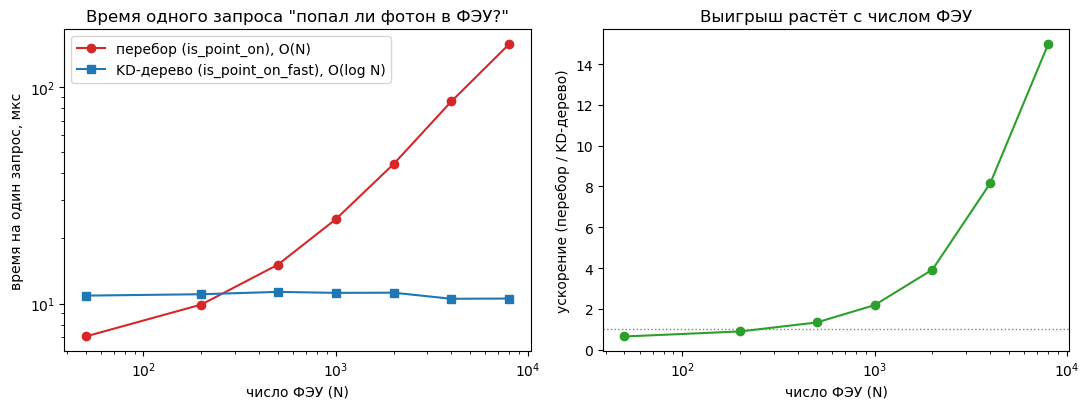

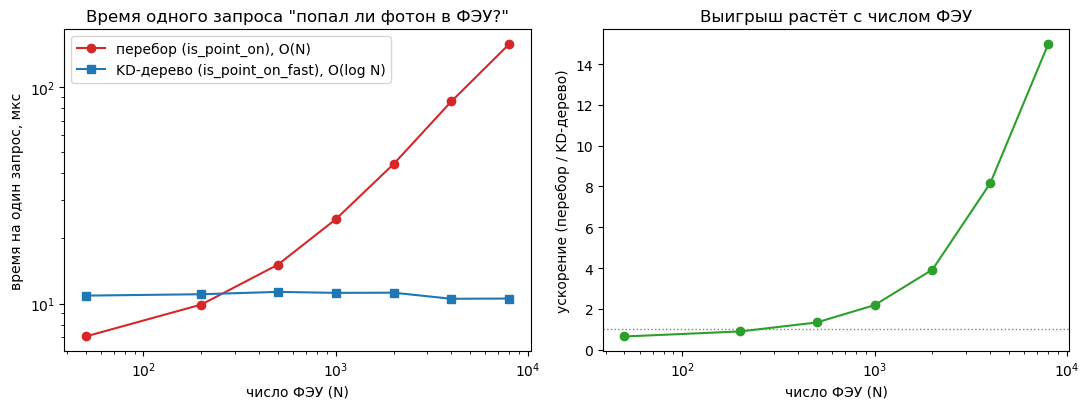

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

axes[0].plot(N_scan, np.array(per_query_linear)*1e6, 'o-', color='tab:red', label='перебор (is_point_on), O(N)')
axes[0].plot(N_scan, np.array(per_query_fast)*1e6, 's-', color='tab:blue', label='KD-дерево (is_point_on_fast), O(log N)')
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_xlabel('число ФЭУ (N)')
axes[0].set_ylabel('время на один запрос, мкс')
axes[0].set_title('Время одного запроса "попал ли фотон в ФЭУ?"')
axes[0].legend()

speedup_scan = np.array(per_query_linear) / np.array(per_query_fast)
axes[1].axhline(1.0, color='gray', linestyle=':', linewidth=1)
axes[1].plot(N_scan, speedup_scan, 'o-', color='tab:green')
axes[1].set_xscale('log')
axes[1].set_xlabel('число ФЭУ (N)')
axes[1].set_ylabel('ускорение (перебор / KD-дерево)')
axes[1].set_title('Выигрыш растёт с числом ФЭУ')

fig.tight_layout()
fig